In [1]:
import sys
import os
from typing import Any, Callable, Dict, List, Optional, Tuple, Iterable, Set

# Add parent directory to path so we can import falling_trees and frame
# script_dir = os.path.dirname(os.path.abspath(__file__))
parent_dir = "/usr/xtmp/vb97/FRL_Rashomon_Set/falling-models"
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import argparse
from falling_trees.binarize_dataset import binarize_dataset
from falling_trees import frl_rashomon_set_alg
from falling_trees.frl_rashomon_set_alg import Node, Leaf, OptFallingTree, OptFallingRset, tree_obj, _subproblem_optimal_objectives, print_tree
from frame.rashomon_sets import FRLRashomonSet
from utils import number_of_terms, frl_accuracy, extract_frl_rules, minimal_conditions, convert_falling_tree_to_falling_rule_list, expected_decision_sparsity_falling_tree, expected_decision_sparsity_frame_frl

def run_comparison(
    dataset_path: str,
    label_column: str = None,
    # Binarization parameters
    num_estimators: int = 50,
    # OptFallingTree parameters
    depth: int = 5,
    lam: float = 0.005,
    enable_falling_constraint: bool = True,
    rule_list_mode: bool = False,
    # OptFallingRset parameters
    eps: float = 0.02,
    use_heap: bool = True,
    # Additional kwargs for both algorithms
    branching_cost: float = 0.01,
    min_support: float = 0.05,
    # Cache settings
    max_cache_size: int = 10**7,
    # FRAME parameters
    frame_epsilon: float = None,
    frame_curiosity_func: str = 'ucb+',
    # Output
    output_file: str = 'frl_rashomon_set_comparison.png',
    max_len: int = 2
):
    """
    Run comparison between Falling Trees and FRAME FRL Rashomon Sets.
    
    Parameters:
    -----------
    dataset_path : str
        Path to the dataset CSV file
    label_column : str, optional
        Name of the label column. If None, uses the last column.
    num_estimators : int
        Number of estimators for binarization
    depth : int
        Maximum depth of the tree
    lam : float
        Regularization parameter (lambda)
    enable_falling_constraint : bool
        Whether to enable the falling tree constraint
    rule_list_mode : bool
        Whether to use rule list mode for optimal tree
    eps : float
        Epsilon for Rashomon set budget (B = best_loss * (1 + eps))
    use_heap : bool
        Whether to use heap for storing trees in Rashomon set
    branching_cost : float
        Cost for branching (internal nodes)
    min_support : float
        Minimum support for splits (as fraction of dataset)
    max_cache_size : int
        Maximum size of the subproblem cache
    frame_epsilon : float, optional
        Epsilon for FRAME. If None, uses the same as eps.
    frame_curiosity_func : str
        Curiosity function for FRAME ('ucb+' or other)
    output_file : str
        Path to save the comparison plot
    """
    # Use frame_epsilon if provided, otherwise use eps
    if frame_epsilon is None:
        frame_epsilon = eps
    
    # Load dataset
    print(f"Loading dataset from {dataset_path}...")
    df = pd.read_csv(dataset_path)
    print(df.shape)
    
    # Binarize dataset
    print(f"Binarizing dataset with {num_estimators} estimators...")
    df, thresholds, header, threshold_guess_time = binarize_dataset(df, num_estimators=num_estimators)
    
    # Extract features and labels
    if label_column is None:
        # Use last column as label
        label_col = df.columns[-1]
        X = df.drop(columns=[label_col])
        y = df[label_col]
    else:
        X = df.drop(columns=[label_column])
        y = df[label_column]

    print(f"Dataset shape: {X.shape[0]} samples, {X.shape[1]} features")
    print(f"Label column: {y.name}")
    print(f"Positive label proportion: {y.mean():.3f}")
    
    features = list(range(X.shape[1]))
    n = X.shape[0]
    row_idx = np.arange(n)
    
    # Set cache size
    frl_rashomon_set_alg.MAX_CACHE_SIZE = max_cache_size
    _subproblem_optimal_objectives.clear()
    
    # Prepare kwargs
    kwargs = {
        "branching_cost": branching_cost,
        "min_support": min_support
    }
    
    # Print parameters
    print("\n" + "="*60)
    print("OptFallingTree Parameters:")
    print(f"  Depth: {depth}")
    print(f"  Lambda (regularization): {lam}")
    print(f"  Enable falling constraint: {enable_falling_constraint}")
    print(f"  Rule list mode: {rule_list_mode}")
    print(f"  Branching cost: {branching_cost}")
    print(f"  Min support: {min_support}")
    print("="*60)
    
    # Run OptFallingTree
    print(f"\nRunning OptFallingTree (depth={depth})...")
    best_loss, best_tree, pmax, depth_of_pmax = OptFallingTree(
        X.values,
        y.values,
        row_idx,
        depth,
        lam,
        features,
        n=n,
        enable_falling_constraint=enable_falling_constraint,
        rule_list_mode=rule_list_mode,
        **kwargs
    )
    
    print(f"Best loss: {best_loss:.4f}")
    print(f"Pmax: {pmax:.4f}")
    print(f"Depth of pmax: {depth_of_pmax}")
    
    # Calculate budget for Rashomon set
    B = best_loss * (1 + eps)
    print(f"\nRashomon set budget: {B:.4f} (best_loss * (1 + {eps}))")
    
    print("\n" + "="*60)
    print("OptFallingRset Parameters:")
    print(f"  Budget (B): {B:.4f}")
    print(f"  Epsilon: {eps}")
    print(f"  Use heap: {use_heap}")
    print("="*60)
    
    # Run OptFallingRset
    print(f"\nRunning OptFallingRset...")
    R = OptFallingRset(
        X.values,
        y.values,
        row_idx,
        depth,
        lam,
        B=B,
        features=features,
        n=n,
        enable_falling_constraint=enable_falling_constraint,
        use_heap=use_heap,
        rule_list_mode=rule_list_mode,
        **kwargs
    )
    print_tree(R[0][0])
    print(f"Found {len(R)} trees in Rashomon set")
    print(f"Cache size: {len(_subproblem_optimal_objectives)}")
    
    # Convert X to boolean for FRAME
    X_bool = X.astype(bool)
    
    # Run FRAME
    print("\n" + "="*60)
    print("FRAME Parameters:")
    print(f"  Epsilon: {frame_epsilon}")
    print(f"  Curiosity function: {frame_curiosity_func}")
    print("="*60)
    
    print(f"\nRunning FRAME...")
    frame_rset = FRLRashomonSet(epsilon=frame_epsilon)
    frame_rset.fit(X_bool, y, curiosity_func=frame_curiosity_func,first_pass_iters=1000,second_pass_iters=1000, max_len = max_len)
    print(f"Found {len(frame_rset.rset)} FRLs in FRAME Rashomon set")
    # Compute metrics
    print("\nComputing metrics...")
    terms_falling_trees = [expected_decision_sparsity_falling_tree(model[0], X.astype(bool).values) for model in R]
    # For FRAME: use the original X (before FRAME modified X_bool in place)
    # The function will automatically expand it if frl.included_complement is True
    # This ensures we're using the same base dataset that FRAME started with
    terms_frame = [expected_decision_sparsity_frame_frl(frl, X.astype(bool)) for frl in frame_rset.rset]
    print(frame_rset.rset[0])
    
    acc_falling_trees = [1 - tree_obj(model[0]) for model in R]
    acc_frame = [frl_accuracy(frl, X_bool, y) for frl in frame_rset.rset]
    return R, frame_rset, terms_falling_trees, terms_frame, acc_falling_trees, acc_frame, X_bool


def count_leaves(tree: Any) -> int:
    """
    Count the number of leaves in a tree.
    """
    if tree is None:
        return 0
    if isinstance(tree, Leaf):
        return 1
    return count_leaves(tree.left) + count_leaves(tree.right)


def colless_index(tree: Any, root = True) -> int:
    """
    Compute the Colless index for a binary tree.
    The Colless index measures tree imbalance by summing the absolute differences
    between the number of leaves in left and right subtrees for all internal nodes.
    
    Returns:
        - 0 for leaves (no internal nodes)
        - int: sum of |left_leaves - right_leaves| over all internal nodes
    """
    if isinstance(tree, Leaf):
        return 0

    if not isinstance(tree, Node):
        return 0
    if isinstance(tree.left, Leaf) and isinstance(tree.right, Leaf) and root:
        return 1

    # Count leaves in left and right subtrees
    left_leaves = count_leaves(tree.left)
    right_leaves = count_leaves(tree.right)

    # Current node's contribution to Colless index
    current_diff = abs(left_leaves - right_leaves)

    # Recursively compute Colless index for subtrees
    left_colless = colless_index(tree.left, root = False)
    right_colless = colless_index(tree.right, root = False)

    return current_diff + left_colless + right_colless
    
def normalized_colless_index(tree: Any) -> float:
    """
    Compute the Normalized Colless index for a binary tree.
    Normalizes the Colless index by dividing by the maximum possible Colless index
    for a tree with the same number of leaves.
    
    The maximum Colless index for a tree with n leaves is (n-1)(n-2)/2
    (achieved by a caterpillar/comb tree).
    
    Returns:
        - 0.0 for leaves (perfectly balanced, single leaf)
        - float: normalized value in [0, 1] where:
            * 0 = perfectly balanced tree
            * 1 = maximally imbalanced tree (caterpillar)
    """
    n = count_leaves(tree)

    # Handle edge cases
    if n <= 1:
        return 0.0

    # Compute raw Colless index
    raw_colless = colless_index(tree)

    # Maximum Colless index for n leaves (caterpillar tree)
    max_colless = (n - 1) * (n - 2) // 2

    if n == 2:
        max_colless = 1
    
    if max_colless == 0:
        return 0.0

    # Normalize
    return raw_colless / max_colless



In [2]:
dataset_path = "/usr/xtmp/vb97/FRL_Rashomon_Set/falling-models/data/benchmark/fico.csv"
num_estimators = 300
depth = 5
lam = 0.02
enable_falling_constraint = True
rule_list_mode = False
eps = 0.02
use_heap = True
branching_cost = 0.01
min_support = 0.01
max_len = 2
max_cache_size = 10**7
frame_epsilon = None
frame_curiosity_func = 'ucb+'
output_file = 'frl_rashomon_set_comparison.png'
R, frame_rset, terms_falling_trees, terms_frame, acc_falling_trees, acc_frame, X_bool = run_comparison(dataset_path, label_column=None, num_estimators=num_estimators, depth=depth, lam=lam, enable_falling_constraint=enable_falling_constraint, rule_list_mode=rule_list_mode, eps=eps, use_heap=use_heap, branching_cost=branching_cost, min_support=min_support, max_cache_size=max_cache_size, frame_epsilon=frame_epsilon, frame_curiosity_func=frame_curiosity_func, output_file=output_file, max_len = max_len)



Loading dataset from /usr/xtmp/vb97/FRL_Rashomon_Set/falling-models/data/benchmark/fico.csv...
(10459, 18)
Binarizing dataset with 300 estimators...


Dataset shape: 10459 samples, 17 features
Label column: RiskPerform
Positive label proportion: 0.478

OptFallingTree Parameters:
  Depth: 5
  Lambda (regularization): 0.02
  Enable falling constraint: True
  Rule list mode: False
  Branching cost: 0.01
  Min support: 0.01

Running OptFallingTree (depth=5)...
Best loss: 0.3065
Pmax: 0.7949
Depth of pmax: 3

Rashomon set budget: 0.3126 (best_loss * (1 + 0.02))

OptFallingRset Parameters:
  Budget (B): 0.3126
  Epsilon: 0.02
  Use heap: True

Running OptFallingRset...
Node(feature=12)
  Node(feature=1)
    Leaf(pred_prob=0.795, objective=0.044)
    Node(feature=16)
      Leaf(pred_prob=0.606, objective=0.004)
      Leaf(pred_prob=0.398, objective=0.063)
  Node(feature=0)
    Leaf(pred_prob=0.668, objective=0.064)
    Leaf(pred_prob=0.262, objective=0.112)
Found 1531 trees in Rashomon set
Cache size: 123448

FRAME Parameters:
  Epsilon: 0.02
  Curiosity function: ucb+

Running FRAME...
Found 172 FRLs in FRAME Rashomon set

Computing metric

In [3]:
k = 0

# sort R by colles index
R.sort(key=lambda x: normalized_colless_index(x[0]) - count_leaves(x[0]))
print_tree(R[k][0])
print(number_of_terms(R[k][0]))
frl = convert_falling_tree_to_falling_rule_list(R[k][0])
# print(number_of_terms_frl(R[k][0]))
print(frame_rset.rset[k])
print(np.mean(terms_frame), np.mean(terms_falling_trees))



Node(feature=8)
  Node(feature=13)
    Leaf(pred_prob=0.797, objective=0.039)
    Node(feature=0)
      Leaf(pred_prob=0.684, objective=0.035)
      Node(feature=16)
        Leaf(pred_prob=0.562, objective=0.005)
        Node(feature=6)
          Leaf(pred_prob=0.549, objective=0.012)
          Leaf(pred_prob=0.360, objective=0.070)
  Node(feature=12)
    Node(feature=0)
      Leaf(pred_prob=0.768, objective=0.006)
      Node(feature=16)
        Leaf(pred_prob=0.613, objective=0.006)
        Node(feature=1)
          Leaf(pred_prob=0.599, objective=0.007)
          Leaf(pred_prob=0.352, objective=0.027)
    Node(feature=0)
      Leaf(pred_prob=0.584, objective=0.015)
      Leaf(pred_prob=0.239, objective=0.070)
14
                                                              Rule Probability    +    -
     if ~TradeFrequency<0.6<=0.5 & ~ExternalRiskEstimate<0.49<=0.5       0.761 2421  759
else if   ~ExternalRiskEstimate<0.65<=0.5 & ~Delinquency<0.75<=0.5       0.550 1087  888
else if  

In [4]:
dataset_path = "/usr/xtmp/vb97/FRL_Rashomon_Set/falling-models/data/benchmark/fico.csv"
num_estimators = 300
df = pd.read_csv(dataset_path)

# Binarize dataset
print(f"Binarizing dataset with {num_estimators} estimators...")
df, thresholds, header, threshold_guess_time = binarize_dataset(df, num_estimators=num_estimators)
print(df.columns,df.shape,)
print(frame_rset.rset[0])
print(expected_decision_sparsity_frame_frl(frame_rset.rset[0], df.iloc[:,:-1]))
print(expected_decision_sparsity_falling_tree(R[k][0], df.iloc[:,:-1].astype(bool).values))
# terms_frame = [expected_decision_sparsity_frame_frl(frl, X_bool) for frl in frame_rset.rset]


Binarizing dataset with 300 estimators...
Index(['ExternalRiskEstimate<0.49<=0.5', 'ExternalRiskEstimate<0.65<=0.5',
       'ExternalRiskEstimate<0.80<=0.5', 'NumSatisfactoryTrades<0.5<=0.5',
       'TradeOpenTime<0.6<=0.5', 'TradeOpenTime<0.85<=0.5',
       'TradeFrequency<0.45<=0.5', 'TradeFrequency<0.6<=0.5',
       'Delinquency<0.55<=0.5', 'Delinquency<0.75<=0.5',
       'Installment<0.5<=0.5', 'Installment<0.7<=0.5', 'Inquiry<0.75<=0.5',
       'RevolvingBalance<0.4<=0.5', 'RevolvingBalance<0.6<=0.5',
       'Utilization<0.6<=0.5', 'TradeWBalance<0.33<=0.5', 'RiskPerform'],
      dtype='object') (10459, 18)
                                                                     Rule Probability    +    -
     if          ~Delinquency<0.55<=0.5 & ~ExternalRiskEstimate<0.65<=0.5       0.712 2782 1127
else if ~ExternalRiskEstimate<0.49<=0.5 & ~NumSatisfactoryTrades<0.5<=0.5       0.694  202   89
else if           ~ExternalRiskEstimate<0.49<=0.5 & ~Installment<0.5<=0.5       0.623  157  

Falling trees: Using 17 original features
FRAME: Using 34 features (with complements)


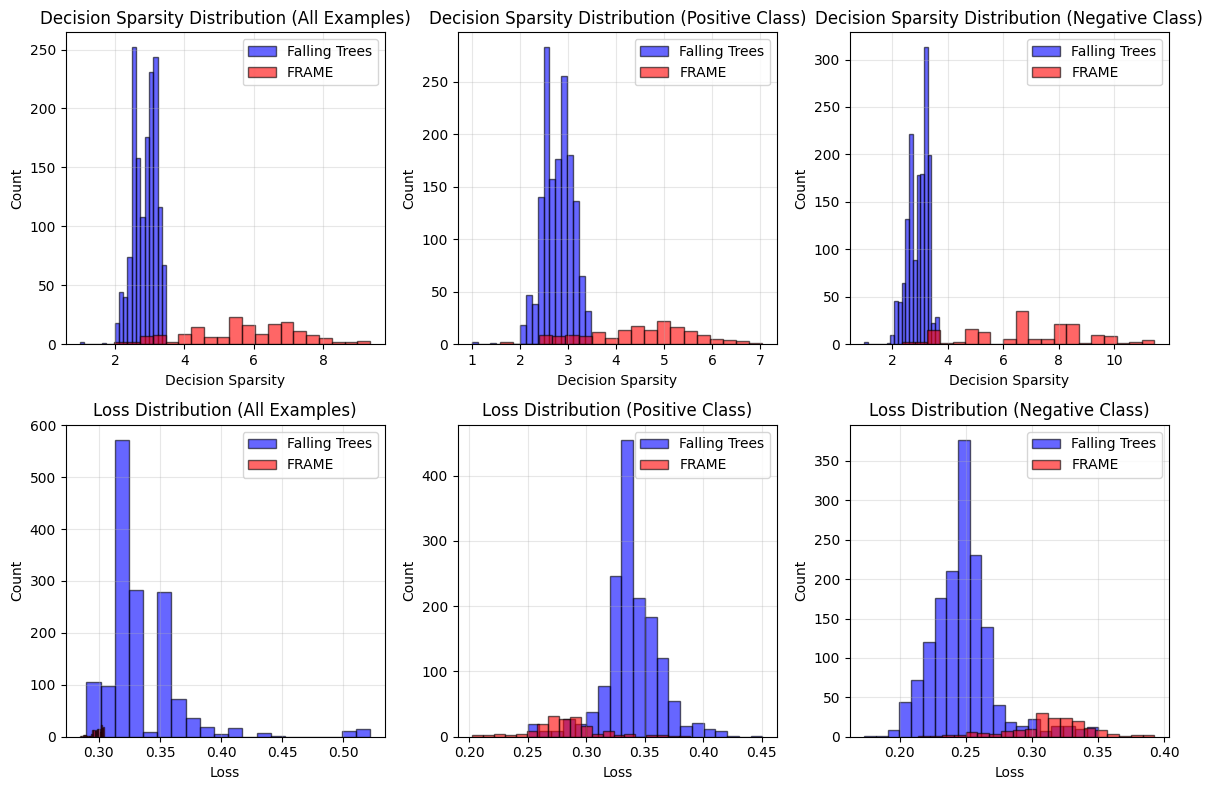

In [ ]:
from falling_trees_vs_frame_runtime import frl_loss, expected_decision_sparsity_frame_frl, compute_frl_loss_by_class, compute_decision_sparsity_by_class_falling_tree, compute_tree_loss_by_class, compute_tree_test_loss, compute_decision_sparsity_by_class_frame_frl
from tqdm import tqdm
from utils import predict_falling_tree, predict_frl, compute_tree_test_loss_threshold
# Load dataset to get y that matches X_bool
dataset_path = "/usr/xtmp/vb97/FRL_Rashomon_Set/falling-models/data/benchmark/fico.csv"
df_full = pd.read_csv(dataset_path)
df_binarized, _, _, _ = binarize_dataset(df_full, num_estimators=300)
y = df_binarized.iloc[:, -1]

threshold = 0.3
# X_bool has been modified by FRAME to include complement features (34 columns)
# Extract only original features for falling trees
original_feature_cols_ft = [col for col in X_bool.columns if not col.startswith('~')]
X_bool_original_ft = X_bool[original_feature_cols_ft]

# Compute decision sparsity distributions
# All examples
terms_ft_all = [expected_decision_sparsity_falling_tree(model[0], X_bool_original_ft.values) for model in R]
terms_frame_all = [expected_decision_sparsity_frame_frl(frl, X_bool) for frl in frame_rset.rset]

# # Positive class
terms_ft_pos = [
    compute_decision_sparsity_by_class_falling_tree(model[0], X_bool_original_ft.values, y.values, 1)
    for model in R
]
terms_frame_pos = [
    compute_decision_sparsity_by_class_frame_frl(frl, X_bool, y, 1)
    for frl in frame_rset.rset
]

# Negative class
terms_ft_neg = [
    compute_decision_sparsity_by_class_falling_tree(model[0], X_bool_original_ft.values, y.values, 0)
    for model in R
]
terms_frame_neg = [
    compute_decision_sparsity_by_class_frame_frl(frl, X_bool, y, 0)
    for frl in frame_rset.rset
]

# CRITICAL FIX: Falling trees were trained on original features only
# But X_bool has been modified by FRAME to include complement features (34 columns)
# Extract only original features for falling trees
original_feature_cols_ft = [col for col in X_bool.columns if not col.startswith('~')]
X_bool_original_ft = X_bool[original_feature_cols_ft]
print(f"Falling trees: Using {len(original_feature_cols_ft)} original features")
print(f"FRAME: Using {X_bool.shape[1]} features (with complements)")

# Compute loss distributions
# All examples
loss_ft_all = [compute_tree_test_loss_threshold(model[0], df_binarized.values, y.values, threshold) for model in R]
loss_frame_all = [frl_loss(frl, X_bool, y) for frl in frame_rset.rset]

# # Positive class
loss_ft_pos = [
    compute_tree_loss_by_class(model[0], df_binarized.values, y.values, 1, threshold)
    for model in R
]
loss_frame_pos = [
    compute_frl_loss_by_class(frl, X_bool, y, 1)
    for frl in frame_rset.rset
]

# # Negative class
loss_ft_neg = [
    compute_tree_loss_by_class(model[0], df_binarized.values, y.values, 0, threshold)
    for model in R
]
loss_frame_neg = [
    compute_frl_loss_by_class(frl, X_bool, y, 0)
    for frl in frame_rset.rset
]

# Create 2x3 subplot (2 rows, 3 columns)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

# Row 0: Decision Sparsity Distributions
# All examples
axes[0, 0].hist(terms_ft_all, bins=20, alpha=0.6, label='Falling Trees', color='blue', edgecolor='black')
axes[0, 0].hist(terms_frame_all, bins=20, alpha=0.6, label='FRAME', color='red', edgecolor='black')
axes[0, 0].set_xlabel('Decision Sparsity')
axes[0, 0].set_ylabel('Count')
axes[0, 0].set_title('Decision Sparsity Distribution (All Examples)')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Positive class
axes[0, 1].hist(terms_ft_pos, bins=20, alpha=0.6, label='Falling Trees', color='blue', edgecolor='black')
axes[0, 1].hist(terms_frame_pos, bins=20, alpha=0.6, label='FRAME', color='red', edgecolor='black')
axes[0, 1].set_xlabel('Decision Sparsity')
axes[0, 1].set_ylabel('Count')
axes[0, 1].set_title('Decision Sparsity Distribution (Positive Class)')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Negative class
axes[0, 2].hist(terms_ft_neg, bins=20, alpha=0.6, label='Falling Trees', color='blue', edgecolor='black')
axes[0, 2].hist(terms_frame_neg, bins=20, alpha=0.6, label='FRAME', color='red', edgecolor='black')
axes[0, 2].set_xlabel('Decision Sparsity')
axes[0, 2].set_ylabel('Count')
axes[0, 2].set_title('Decision Sparsity Distribution (Negative Class)')
axes[0, 2].legend()
axes[0, 2].grid(alpha=0.3)

# Row 1: Loss Distributions
# All examples
axes[1, 0].hist(loss_ft_all, bins=20, alpha=0.6, label='Falling Trees', color='blue', edgecolor='black')
axes[1, 0].hist(loss_frame_all, bins=20, alpha=0.6, label='FRAME', color='red', edgecolor='black')
axes[1, 0].set_xlabel('Loss')
axes[1, 0].set_ylabel('Count')
axes[1, 0].set_title('Loss Distribution (All Examples)')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Positive class
axes[1, 1].hist(loss_ft_pos, bins=20, alpha=0.6, label='Falling Trees', color='blue', edgecolor='black')
axes[1, 1].hist(loss_frame_pos, bins=20, alpha=0.6, label='FRAME', color='red', edgecolor='black')
axes[1, 1].set_xlabel('Loss')
axes[1, 1].set_ylabel('Count')
axes[1, 1].set_title('Loss Distribution (Positive Class)')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

# Negative class
axes[1, 2].hist(loss_ft_neg, bins=20, alpha=0.6, label='Falling Trees', color='blue', edgecolor='black')
axes[1, 2].hist(loss_frame_neg, bins=20, alpha=0.6, label='FRAME', color='red', edgecolor='black')
axes[1, 2].set_xlabel('Loss')
axes[1, 2].set_ylabel('Count')
axes[1, 2].set_title('Loss Distribution (Negative Class)')
axes[1, 2].legend()
axes[1, 2].grid(alpha=0.3)

plt.tight_layout()
plt.show()




X_bool shape: (10459, 34)
Reference features shape: 34
First few reference features: ['ExternalRiskEstimate<0.49<=0.5', 'ExternalRiskEstimate<0.65<=0.5', 'ExternalRiskEstimate<0.80<=0.5', 'NumSatisfactoryTrades<0.5<=0.5', 'TradeOpenTime<0.6<=0.5']
First few X_bool columns: ['ExternalRiskEstimate<0.49<=0.5', 'ExternalRiskEstimate<0.65<=0.5', 'ExternalRiskEstimate<0.80<=0.5', 'NumSatisfactoryTrades<0.5<=0.5', 'TradeOpenTime<0.6<=0.5']


 20%|█▉        | 300/1531 [00:00<00:03, 388.07it/s]

100%|██████████| 19/19 [00:00<00:00, 317.10it/s]


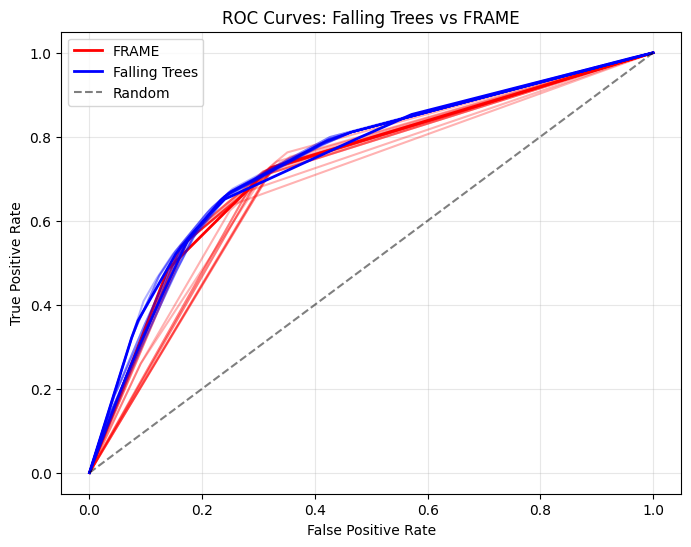

In [7]:
from sklearn.metrics import roc_curve
from utils import predict_proba_falling_tree
from tqdm import tqdm

# Use the X_bool from run_comparison which already has the correct feature order
# OR if creating manually, ensure columns match frl.features order
# The issue: FRAME's rule_list uses numeric indices that refer to positions in frl.features
# So the column order in X_bool must match frl.features exactly

# Option 1: Use X_bool from run_comparison (already correctly ordered)
# X_bool is already available from run_comparison output

# Option 2: If creating manually, reorder to match reference_features
# Get the reference features (same order as all FRLs in the Rashomon set)
reference_features = frame_rset.reference_model.features

# Create X_bool with correct feature order
dataset_path = "/usr/xtmp/vb97/FRL_Rashomon_Set/falling-models/data/benchmark/fico.csv"
df = pd.read_csv(dataset_path)
df_binarized, _, _, _ = binarize_dataset(df, num_estimators=300)
y = df_binarized.iloc[:, -1]

# Create X_bool with complement features, matching the order from FRAME training
X_bool_manual = df_binarized.iloc[:, :-1].astype(bool).copy()
if hasattr(frame_rset.reference_model, 'included_complement') and frame_rset.reference_model.included_complement:
    # Add complement features
    original_cols = list(X_bool_manual.columns)
    for col in original_cols:
        X_bool_manual['~' + col] = ~X_bool_manual[col]

# CRITICAL: Reorder columns to match reference_features order
# Add any missing columns (shouldn't happen, but defensive)
for feat in reference_features:
    if feat not in X_bool_manual.columns:
        print(f"Warning: Feature {feat} not found in X_bool_manual, adding zeros")
        X_bool_manual[feat] = False
# Reorder to match reference_features exactly
X_bool = X_bool_manual[reference_features]

print(f"X_bool shape: {X_bool.shape}")
print(f"Reference features shape: {len(reference_features)}")
print(f"First few reference features: {list(reference_features[:5])}")
print(f"First few X_bool columns: {list(X_bool.columns[:5])}")

threshold = 0.9
roc_frame = []
for frl in tqdm(frame_rset.rset):
    # Ensure X_bool columns match this frl's features order (should be same as reference_features)
    X_bool_reordered = X_bool[frl.features] if hasattr(frl, 'features') else X_bool
    frl_probs = frl.predict_proba(X_bool_reordered)
    fpr, tpr, _ = roc_curve(y.values, frl_probs)
    roc_frame.append({'fpr': fpr, 'tpr': tpr})

roc_falling_trees = []
for model in tqdm(R):
    model_probs = predict_proba_falling_tree(model[0], X_bool.values)
    fpr, tpr, _ = roc_curve(y.values, model_probs)
    roc_falling_trees.append({'fpr': fpr, 'tpr': tpr})

fig, ax = plt.subplots(1,1, figsize=(8, 6))
plt.plot(roc_frame[0]['fpr'], roc_frame[0]['tpr'], label = "FRAME", color='red', linewidth=2)
for roc in tqdm(roc_frame[1:20]):
    plt.plot(roc['fpr'], roc['tpr'], alpha = 0.3, label = "_nolegend_",color='r')

plt.plot(roc_falling_trees[0]['fpr'], roc_falling_trees[0]['tpr'], label = "Falling Trees", color='blue', linewidth=2)
for roc in tqdm(roc_falling_trees[1:20]):
    plt.plot(roc['fpr'], roc['tpr'], alpha = 0.3, label = "_nolegend_",color='b')

# Add diagonal reference line
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves: Falling Trees vs FRAME')
plt.legend()
plt.grid(alpha=0.3)
plt.show()



Binarizing...
Training Falling Trees...
Training FRAME...


/usr/project/xtmp/vb97/FRL_Rashomon_Set/frl_rashomon_set/lib/python3.10/site-packages/mlxtend/frequent_patterns/fpcommon.py:161: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


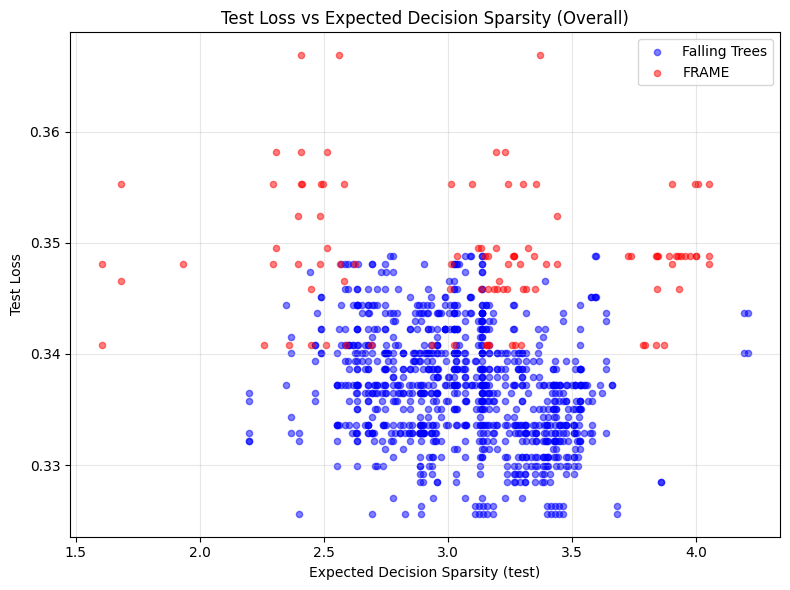

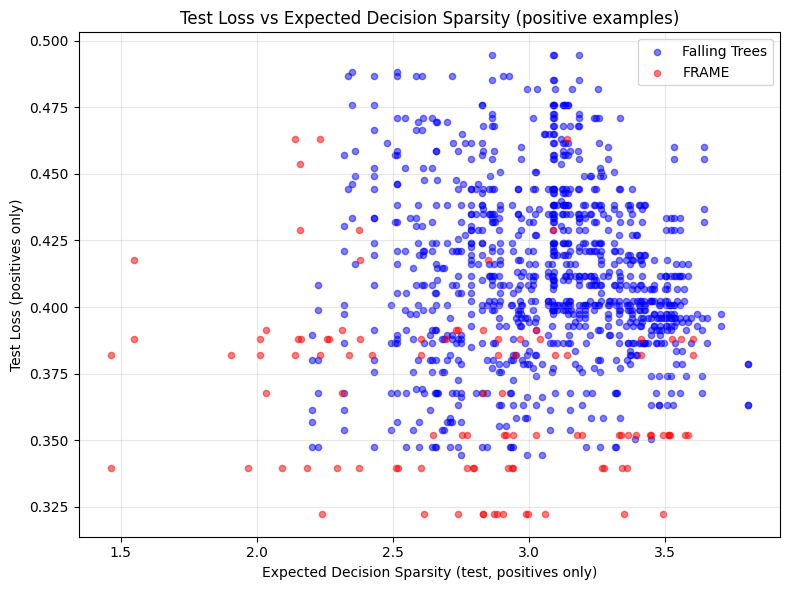

In [9]:
# One-split scatter: test loss vs expected decision sparsity
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
# Experimental: Falling Trees (C++ backend) vs FRAME on COMPAS (binarized)
from pathlib import Path
import tempfile
import time
import sys
sys.path.append("/usr/xtmp/vb97/FRL_Rashomon_Set/falling-models/")
sys.path.append("/usr/xtmp/vb97/FRL_Rashomon_Set/falling-models/frame/")
import pandas as pd
import os
from falling_trees import falling_rashomon_cpp as gravitree
from falling_trees.check_cpp_rset_falling import load_cpp_rset
from falling_trees.binarize_dataset import binarize_dataset
from rashomon_sets import FRLRashomonSet
import random
import numpy as np
from utils import (
    expected_decision_sparsity_falling_tree,
    expected_decision_sparsity_frame_frl,
    compute_tree_test_loss_threshold,
)
from tqdm import tqdm
seed = 42
random.seed(seed)
np.random.seed(seed)

# Defaults (use existing globals if defined)
dataset_path = "/usr/xtmp/vb97/FRL_Rashomon_Set/falling-models/data/benchmark/compas.csv"
label_column_local = None
num_estimators_local = 50
depth_local = 5
lam_local = 0.005
eps_local = 0.02
branching_cost_local = 0.005
min_support_local = 0.05
use_heap_local = True
rule_list_mode_local = False
max_cache_size_local = 10**7
frame_curiosity_func_local = "ucb+"
max_len_local = 1

# Fallback rebalance if not defined
if "rebalance_if_imbalanced" not in globals():
    def rebalance_if_imbalanced(df, label_col, random_state=None):
        counts = df[label_col].value_counts()
        if len(counts) < 2:
            return df
        majority_count = counts.max()
        minority_count = counts.min()
        total = len(df)
        if total == 0 or minority_count == 0:
            return df
        majority_frac = majority_count / total
        minority_frac = minority_count / total
        if majority_frac <= 0.7 and minority_frac >= 0.3:
            return df
        minority_label = counts.idxmin()
        minority_df = df[df[label_col] == minority_label]
        add_n = majority_count - minority_count
        if add_n <= 0:
            return df
        sampled = minority_df.sample(n=add_n, replace=True, random_state=random_state)
        return pd.concat([df, sampled], ignore_index=True)


def _build_frame_bool_local(X_df, reference_model):
    X_bool = X_df.astype(bool).copy()
    if hasattr(reference_model, "included_complement") and reference_model.included_complement:
        original_cols = list(X_bool.columns)
        for col in original_cols:
            X_bool["~" + col] = ~X_bool[col]
    reference_features = getattr(reference_model, "features", list(X_bool.columns))
    for feat in reference_features:
        if feat not in X_bool.columns:
            X_bool[feat] = False
    return X_bool[reference_features]


# Load and split
compas_df_local = pd.read_csv(dataset_path)
label_col_local = compas_df_local.columns[-1] if label_column_local is None else label_column_local

train_df, test_df = train_test_split(
    compas_df_local,
    test_size=0.2,
    random_state=0,
    stratify=compas_df_local[label_col_local],
)
train_df = rebalance_if_imbalanced(train_df, label_col_local, random_state=0)

print("Binarizing...")
# Binarize
train_bin, thresholds, header, _ = binarize_dataset(
    train_df, num_estimators=num_estimators_local
)
test_bin = binarize_dataset(
    test_df, num_estimators=num_estimators_local, thresholds=thresholds, header=header
)

X_train = train_bin.drop(columns=[label_col_local])
y_train = train_bin[label_col_local]
X_test = test_bin.drop(columns=[label_col_local])
y_test = test_bin[label_col_local]

print("Training Falling Trees...")
# Falling Trees (C++)
with tempfile.NamedTemporaryFile(suffix=".jsonl", delete=False) as tmp_file:
    dump_path = tmp_file.name

result = gravitree.run_from_xy(
    X_train.values,
    y_train.values,
    lam=lam_local,
    eps=eps_local,
    depth=depth_local,
    enable_falling_constraint=True,
    use_heap=use_heap_local,
    rule_list_mode=rule_list_mode_local,
    branching_cost=branching_cost_local,
    min_support=min_support_local,
    use_current_leaf_prob=True,
    budget_override=None,
    dump_rset_jsonl=dump_path,
    max_cache_size=max_cache_size_local,
)

best_loss = float(result["best_loss"])
ft_rset = load_cpp_rset(dump_path)
os.remove(dump_path)
print("Training FRAME...")
# FRAME
frame_absolute_budget = best_loss + eps_local
frame_rset = FRLRashomonSet(epsilon=eps_local)
frame_rset.fit(
    X_train.astype(bool),
    y_train,
    curiosity_func=frame_curiosity_func_local,
    first_pass_iters=1000,
    second_pass_iters=10000,
    max_len=max_len_local,
    absolute_budget=frame_absolute_budget,
    min_support=min_support_local,
)

# Compute per-model metrics on test
ft_sparsity = [
    expected_decision_sparsity_falling_tree(model[0], X_test.astype(bool).values)
    for model in ft_rset
]
ft_loss = [
    compute_tree_test_loss_threshold(model[0], X_test.values, y_test.values, threshold=0.5)
    for model in ft_rset
]

X_test_bool = _build_frame_bool_local(X_test, frame_rset.reference_model)
frame_sparsity = [
    expected_decision_sparsity_frame_frl(frl, X_test_bool)
    for frl in frame_rset.rset
]
frame_loss = [
    float(np.mean(frl.predict(X_test_bool) != y_test.values))
    for frl in frame_rset.rset
]

# Scatter plot
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.scatter(ft_sparsity, ft_loss, s=20, alpha=0.5, label="Falling Trees", color="blue")
ax.scatter(frame_sparsity, frame_loss, s=20, alpha=0.5, label="FRAME", color="red")
ax.set_xlabel("Expected Decision Sparsity (test)")
ax.set_ylabel("Test Loss")
ax.set_title("Test Loss vs Expected Decision Sparsity (Overall)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Compute expected sparsity and test loss on positive examples only
positive_indices = np.where(y_test.values == 1)[0]

# Falling Trees
ft_sparsity_pos = [
    expected_decision_sparsity_falling_tree(model[0], X_test.iloc[positive_indices].astype(bool).values)
    for model in ft_rset
]
ft_loss_pos = [
    compute_tree_test_loss_threshold(model[0], X_test.iloc[positive_indices].values, y_test.values[positive_indices], threshold=0.5)
    for model in ft_rset
]

# FRAME
X_test_bool_pos = _build_frame_bool_local(X_test.iloc[positive_indices], frame_rset.reference_model)
frame_sparsity_pos = [
    expected_decision_sparsity_frame_frl(frl, X_test_bool_pos)
    for frl in frame_rset.rset
]
frame_loss_pos = [
    float(np.mean(frl.predict(X_test_bool_pos) != y_test.values[positive_indices]))
    for frl in frame_rset.rset
]

# Scatter plot for positive examples
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.scatter(ft_sparsity_pos, ft_loss_pos, s=20, alpha=0.5, label="Falling Trees", color="blue")
ax.scatter(frame_sparsity_pos, frame_loss_pos, s=20, alpha=0.5, label="FRAME", color="red")
ax.set_xlabel("Expected Decision Sparsity (test, positives only)")
ax.set_ylabel("Test Loss (positives only)")
ax.set_title("Test Loss vs Expected Decision Sparsity (positive examples)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## Falling Trees vs Regular Trees

In [ ]:
# Compare Falling Trees vs Regular Trees on COMPAS (with oversampling)
from sklearn.model_selection import train_test_split

# Experimental: Falling Trees (C++ backend) vs FRAME on COMPAS (binarized)
from pathlib import Path
import tempfile
import time
import sys
sys.path.append("/usr/xtmp/vb97/FRL_Rashomon_Set/falling-models/")
sys.path.append("/usr/xtmp/vb97/FRL_Rashomon_Set/falling-models/frame/")
from falling_trees.frl_rashomon_set_alg_falling_constraint_v2 import print_tree
import pandas as pd
import os
from falling_trees import falling_rashomon_cpp as gravitree
# from falling_trees.check_cpp_rset_falling import load_cpp_rset
from falling_trees.binarize_dataset import binarize_dataset
from rashomon_sets import FRLRashomonSet
import random
import numpy as np
from utils import (
    expected_decision_sparsity_falling_tree,
    expected_decision_sparsity_frame_frl,
    compute_tree_test_loss_threshold,
)
from tqdm import tqdm
seed = 42
random.seed(seed)
np.random.seed(seed)

compas_path = "/usr/xtmp/vb97/FRL_Rashomon_Set/falling-models/data/benchmark/compas.csv"
label_column = None

# Parameters (shared)
num_estimators = 30
depth = 5
lam = 0.005
eps = 0.02
branching_cost = 0.01
min_support = 0.05
use_heap = True
max_cache_size = 10**7

def rebalance_if_imbalanced(df, label_col, random_state=None):
    """Minority oversampling if class balance exceeds 70/30."""
    counts = df[label_col].value_counts()
    if len(counts) < 2:
        return df
    majority_count = counts.max()
    minority_count = counts.min()
    total = len(df)
    if total == 0 or minority_count == 0:
        return df
    majority_frac = majority_count / total
    minority_frac = minority_count / total
    if majority_frac <= 0.7 and minority_frac >= 0.3:
        return df
    minority_label = counts.idxmin()
    minority_df = df[df[label_col] == minority_label]
    add_n = majority_count - minority_count
    if add_n <= 0:
        return df
    sampled = minority_df.sample(n=add_n, replace=True, random_state=random_state)
    return pd.concat([df, sampled], ignore_index=True)


n_splits = 5
ft_sizes, reg_sizes = [], []
ft_times, reg_times = [], []
ft_sparsity_means, reg_sparsity_means = [], []
ft_test_loss_means, reg_test_loss_means = [], []
ft_sparsity_on_positive_examples_means, reg_sparsity_on_positive_examples_means = [], []
ft_loss_on_positive_examples_means, reg_loss_on_positive_examples_means = [], []

for split_idx in range(n_splits):
    print(f"\nSplit {split_idx + 1}/{n_splits}")
    compas_df = pd.read_csv(compas_path)
    if label_column is None:
        label_col = compas_df.columns[-1]
    else:
        label_col = label_column
    train_df, test_df = train_test_split(
        compas_df,
        test_size=0.2,
        random_state=split_idx,
        stratify=compas_df[label_col],
    )
    train_df = rebalance_if_imbalanced(train_df, label_col, random_state=split_idx)

    train_bin, thresholds, header, _ = binarize_dataset(
        train_df, num_estimators=num_estimators
    )
    test_bin = binarize_dataset(
        test_df, num_estimators=num_estimators, thresholds=thresholds, header=header
    )

    X_train = train_bin.drop(columns=[label_col])
    y_train = train_bin[label_col]
    X_test = test_bin.drop(columns=[label_col])
    y_test = test_bin[label_col]

    # Falling constraint ON
    with tempfile.NamedTemporaryFile(suffix=".jsonl", delete=False) as tmp_file:
        dump_path = tmp_file.name
    print("training gravitree with falling constraint")
    print(X_train.values.shape)
    start_time = time.time()
    result_on = gravitree.run_from_xy(
        X_train.values,
        y_train.values,
        lam=lam,
        eps=eps,
        depth=depth,
        enable_falling_constraint=True,
        use_heap=use_heap,
        branching_cost=branching_cost,
        min_support=min_support,
        use_current_leaf_prob=True,
        budget_override=None,
        dump_rset_jsonl=dump_path,
        max_cache_size=max_cache_size,
    )
    ft_time = time.time() - start_time
    best_loss_on = float(result_on["best_loss"])
    budget_on = best_loss_on * (1 + eps)
    # ft_rset = load_cpp_rset(dump_path)
    # print_tree(ft_rset[0][0])
    os.remove(dump_path)
    
    # Falling constraint OFF (regular trees), with same budget
    with tempfile.NamedTemporaryFile(suffix=".jsonl", delete=False) as tmp_file:
        dump_path = tmp_file.name
    print("training gravitree without falling constraint")
    start_time = time.time()
    result_off = gravitree.run_from_xy(
        X_train.values,
        y_train.values,
        lam=lam,
        eps=eps,
        depth=depth,
        enable_falling_constraint=False,
        use_heap=use_heap,
        branching_cost=branching_cost,
        min_support=min_support,
        use_current_leaf_prob=True,
        budget_override=budget_on,
        dump_rset_jsonl=dump_path,
        max_cache_size=max_cache_size,
    )
    reg_time = time.time() - start_time
    # reg_rset = load_cpp_rset(dump_path)
    os.remove(dump_path)

#     # Metrics on test split
#     ft_sparsity = [
#         expected_decision_sparsity_falling_tree(model[0], X_test.astype(bool).values)
#         for model in ft_rset
#     ]
#     ft_loss = [
#         compute_tree_test_loss_threshold(model[0], X_test.values, y_test.values, threshold=0.5)
#         for model in ft_rset
#     ]
#     reg_sparsity = [
#         expected_decision_sparsity_falling_tree(model[0], X_test.astype(bool).values)
#         for model in reg_rset
#     ]
#     reg_loss = [
#         compute_tree_test_loss_threshold(model[0], X_test.values, y_test.values, threshold=0.5)
#         for model in reg_rset
#     ]
#     ft_sparsity_on_positive_examples = [
#         expected_decision_sparsity_falling_tree(model[0], X_test[y_test == 1].astype(bool).values)
#         for model in ft_rset
#     ]
#     ft_loss_on_positive_examples = [
#         compute_tree_test_loss_threshold(model[0], X_test[y_test == 1].values, y_test[y_test == 1].values, threshold=0.5) 
#         for model in ft_rset
#     ]
#     reg_sparsity_on_positive_examples = [
#         expected_decision_sparsity_falling_tree(model[0], X_test[y_test == 1].astype(bool).values)
#         for model in reg_rset
#     ]
#     reg_loss_on_positive_examples = [
#         compute_tree_test_loss_threshold(model[0], X_test[y_test == 1].values, y_test[y_test == 1].values, threshold=0.5)
#         for model in reg_rset
#     ]

#     ft_sizes.append(len(ft_rset))
#     reg_sizes.append(len(reg_rset))
#     ft_times.append(ft_time)
#     reg_times.append(reg_time)
#     ft_sparsity_means.append(float(np.mean(ft_sparsity)) if ft_sparsity else 0.0)
#     reg_sparsity_means.append(float(np.mean(reg_sparsity)) if reg_sparsity else 0.0)
#     ft_test_loss_means.append(float(np.mean(ft_loss)) if ft_loss else 0.0)
#     reg_test_loss_means.append(float(np.mean(reg_loss)) if reg_loss else 0.0)
#     ft_sparsity_on_positive_examples_means.append(float(np.mean(ft_sparsity_on_positive_examples)) if ft_sparsity_on_positive_examples else 0.0)
#     reg_sparsity_on_positive_examples_means.append(float(np.mean(reg_sparsity_on_positive_examples)) if reg_sparsity_on_positive_examples else 0.0)
#     ft_loss_on_positive_examples_means.append(float(np.mean(ft_loss_on_positive_examples)) if ft_loss_on_positive_examples else 0.0)
#     reg_loss_on_positive_examples_means.append(float(np.mean(reg_loss_on_positive_examples)) if reg_loss_on_positive_examples else 0.0)

#     print(
#         f"Falling ON rset={len(ft_rset)} time={ft_time:.2f}s | "
#         f"Regular rset={len(reg_rset)} time={reg_time:.2f}s"
#     )

# print("\nSummary over splits (Falling vs Regular):")
# print(f"Falling rset size: mean={np.mean(ft_sizes):.1f}, std={np.std(ft_sizes):.1f}")
# print(f"Regular rset size: mean={np.mean(reg_sizes):.1f}, std={np.std(reg_sizes):.1f}")
# print(f"Falling time (s): mean={np.mean(ft_times):.2f}, std={np.std(ft_times):.2f}")
# print(f"Regular time (s): mean={np.mean(reg_times):.2f}, std={np.std(reg_times):.2f}")
# print(f"Falling test sparsity: mean={np.mean(ft_sparsity_means):.2f}, std={np.std(ft_sparsity_means):.2f}")
# print(f"Regular test sparsity: mean={np.mean(reg_sparsity_means):.2f}, std={np.std(reg_sparsity_means):.2f}")
# print(f"Falling test loss: mean={np.mean(ft_test_loss_means):.3f}, std={np.std(ft_test_loss_means):.3f}")
# print(f"Regular test loss: mean={np.mean(reg_test_loss_means):.3f}, std={np.std(reg_test_loss_means):.3f}")
# print(f"Falling test sparsity on positive examples: mean={np.mean(ft_sparsity_on_positive_examples_means):.2f}, std={np.std(ft_sparsity_on_positive_examples_means):.2f}")
# print(f"Regular test sparsity on positive examples: mean={np.mean(reg_sparsity_on_positive_examples_means):.2f}, std={np.std(reg_sparsity_on_positive_examples_means):.2f}")
# print(f"Falling test loss on positive examples: mean={np.mean(ft_loss_on_positive_examples_means):.3f}, std={np.std(ft_loss_on_positive_examples_means):.3f}")
# print(f"Regular test loss on positive examples: mean={np.mean(reg_loss_on_positive_examples_means):.3f}, std={np.std(reg_loss_on_positive_examples_means):.3f}")



Split 1/5
training gravitree with falling constraint
(5525, 17)


In [1]:
from sklearn.model_selection import train_test_split

# Experimental: Falling Trees (C++ backend) vs FRAME on COMPAS (binarized)
from pathlib import Path
import tempfile
import time
import sys
sys.path.append("/usr/project/xtmp/vb97/FRL_Rashomon_Set/falling-models/")
sys.path.append("/usr/project/xtmp/vb97/FRL_Rashomon_Set/falling-models/frame/")
from falling_trees.frl_rashomon_set_alg_falling_constraint_v2 import print_tree
import pandas as pd
import os
from falling_trees import falling_rashomon_cpp as gravitree
from falling_trees.check_cpp_rset_falling import load_cpp_rset
from falling_trees.binarize_dataset import binarize_dataset
from rashomon_sets import FRLRashomonSet
import random
import numpy as np
from utils import (
    expected_decision_sparsity_falling_tree,
    expected_decision_sparsity_frame_frl,
    compute_tree_test_loss_threshold,
)
from tqdm import tqdm
seed = 42
random.seed(seed)
np.random.seed(seed)
compas_path = "/usr/project/xtmp/vb97/FRL_Rashomon_Set/falling-models/data/benchmark/compas.csv"




In [2]:
# Parameters (shared)
num_estimators = 100
depth = 5
lam = 0.00
quantized_cache_level = 0.001
eps = 0.02
branching_cost = 0.01
min_support = 0.02
use_heap = True
max_cache_size = 10**7
dump_path = "rset.jsonl"
recurse_on_lower_prob_first = False


In [ ]:
# df = pd.read_csv(compas_path)
# df_binarized, _, _, _ = binarize_dataset(df, num_estimators=num_estimators)
# y = df_binarized.iloc[:, -1]
# X = df_binarized.iloc[:, :-1]
# print(X.shape)

# dump_path = "rset.jsonl"
# result = gravitree.run_from_xy(
#         X.values,
#         y.values,
#         lam=lam,
#         eps=eps,
#         depth=depth,
#         enable_falling_constraint=True,
#         use_heap=use_heap,
#         branching_cost=branching_cost,
#         min_support=min_support,
#         use_current_leaf_prob=True,
#         budget_override=None,
#         dump_rset_jsonl=dump_path,
#         max_cache_size=max_cache_size,
#         recurse_on_lower_prob_first = False
#     )
# rset = load_cpp_rset(dump_path)
print(len(rset))


In [ ]:
dump_path_lower = "rset_lower_prob_first.jsonl"
print("Running with lower prob first")
result_lower_prob_first = gravitree.run_from_xy(
        X.values,
        y.values,
        lam=lam,
        eps=eps,
        depth=depth,
        enable_falling_constraint=True,
        use_heap=use_heap,
        branching_cost=branching_cost,
        min_support=min_support,
        use_current_leaf_prob=True,
        budget_override=None,
        dump_rset_jsonl=dump_path_lower,
        max_cache_size=max_cache_size,
        recurse_on_lower_prob_first = True
    )

print("Running with higher prob first")
dump_path_higher = "rset_higher_prob_first.jsonl"

result_higher_prob_first = gravitree.run_from_xy(
        X.values,
        y.values,
        lam=lam,
        eps=eps,
        depth=depth,
        enable_falling_constraint=True,
        use_heap=use_heap,
        branching_cost=branching_cost,
        min_support=min_support,
        use_current_leaf_prob=True,
        budget_override=None,
        dump_rset_jsonl=dump_path_higher,
        max_cache_size=max_cache_size,
        recurse_on_lower_prob_first = False
    )


In [30]:
ft_rset_lower_prob_first = load_cpp_rset(dump_path_lower)
print(result_lower_prob_first)

{'best_loss': 0.11106498587263637, 'pmax': 0.9798319327731092, 'rset_size': 3, 'best_tree_str': 'Node(feature=15)\n  Node(feature=1)\n    Node(feature=8)\n      Node(feature=3)\n        Leaf(pred_prob=0.060, objective=0.028)\n        Leaf(pred_prob=0.311, objective=0.012)\n      Leaf(pred_prob=0.648, objective=0.008)\n    Leaf(pred_prob=0.847, objective=0.006)\n  Node(feature=1)\n    Node(feature=19)\n      Node(feature=25)\n        Node(feature=4)\n          Leaf(pred_prob=0.176, objective=0.020)\n          Leaf(pred_prob=0.682, objective=0.009)\n        Leaf(pred_prob=0.806, objective=0.007)\n      Leaf(pred_prob=0.935, objective=0.008)\n    Leaf(pred_prob=0.980, objective=0.003)\n', 'cache_size': 1594055, 'cache_hits': 5365540, 'cache_misses': 3907035, 'non_falling_new': 0}


In [31]:
ft_rset_higher_prob_first = load_cpp_rset(dump_path_higher)
print(result_higher_prob_first)

{'best_loss': 0.11106498587263637, 'pmax': 0.9798319327731092, 'rset_size': 69, 'best_tree_str': 'Node(feature=15)\n  Node(feature=1)\n    Node(feature=8)\n      Node(feature=3)\n        Leaf(pred_prob=0.060, objective=0.028)\n        Leaf(pred_prob=0.311, objective=0.012)\n      Leaf(pred_prob=0.648, objective=0.008)\n    Leaf(pred_prob=0.847, objective=0.006)\n  Node(feature=1)\n    Node(feature=19)\n      Node(feature=25)\n        Node(feature=4)\n          Leaf(pred_prob=0.176, objective=0.020)\n          Leaf(pred_prob=0.682, objective=0.009)\n        Leaf(pred_prob=0.806, objective=0.007)\n      Leaf(pred_prob=0.935, objective=0.008)\n    Leaf(pred_prob=0.980, objective=0.003)\n', 'cache_size': 6001598, 'cache_hits': 22313748, 'cache_misses': 18767087, 'non_falling_new': 0}


In [ ]:
# Check if all the lower prob first trees are in the higher prob first Rashomon set
from tqdm import tqdm

def trees_to_hash_set(rset):
    # Each tree is an object, use its canonical string representation for set membership
    # ft_rset elements: (loss, tree, extra)
    return set(t for (_, t, *_) in rset)

hashes_higher = trees_to_hash_set(ft_rset_higher_prob_first)
hashes_lower = trees_to_hash_set(ft_rset_lower_prob_first)

missing = []
for (_, t, *_) in tqdm(ft_rset_lower_prob_first):
    # t_repr = print_tree(t)
    if t_repr not in hashes_higher:
        missing.append(t)

if not missing:
    print("All lower prob first trees are present in the higher prob first Rashomon set.")
else:
    print(f"{len(missing)} trees from lower prob first are missing in higher prob first Rashomon set!")
    # Optionally print some:
    for i, t in enumerate(missing[:3]):
        print(f"Missing tree {i+1}:")
        # print(print_tree(t, ret_string=True))


NameError: name 'ft_rset_higher_prob_first' is not defined

In [29]:
print_tree(ft_rset_lower_prob_first[1][0])

Node(feature=1)
  Node(feature=15)
    Node(feature=8)
      Leaf(pred_prob=0.079, objective=0.041)
      Leaf(pred_prob=0.648, objective=0.008)
    Node(feature=24)
      Node(feature=19)
        Node(feature=2)
          Leaf(pred_prob=0.141, objective=0.014)
          Leaf(pred_prob=0.598, objective=0.008)
        Leaf(pred_prob=0.823, objective=0.005)
      Leaf(pred_prob=0.875, objective=0.018)
  Leaf(pred_prob=0.948, objective=0.009)
